In [ ]:
# --- 🔧 Install dan Import Library ---
!pip install mlxtend openpyxl --quiet

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
file_path = '/content/drive/MyDrive/AsosiasiAi/data_retail2.xlsx'
df = pd.read_excel(file_path)
df.head()

,InvoiceNo,InvoiceDate,BRANCH_SPLR,BRANCHNAME_SPLR,warehouseProductsID,BARCODEID,StockCode,PRODUCT,PRODUCT_CATEGORY,Quantity,...,CustomerID,CUSTNAME,ADDRESS,KOTA,PROVINSI,NEGARA,CHANNELID_SPLR,CHANNELNAME_SPLR,SUBDISTID,SUBDIST_NAME
0,536365,2020-12-01 08:26:00,13,SAMARINDA,10001,8992753282401,85123A,123 BENDERA COKLAT 300G,SUSU,6,...,17850.0,DUA PUTRI SLAMET RIYADI,JL. SLAMET RIYADI,SAMARINDA,KALIMANTAN TIMUR,INDONESIA,32,Toko Kelontong,130113,CV. EKA PUTRA
1,536365,2020-12-01 08:26:00,13,SAMARINDA,20020,8999909192034,71053,2.3.4 FILTER,ROKOK,6,...,17850.0,SANURI,JL. M. SAID,SAMARINDA,KALIMANTAN TIMUR,INDONESIA,32,Toko Kelontong,130113,CV. EKA PUTRA
2,536365,2020-12-01 08:26:00,19,YOGYAKARTA,20021,8999909007147,84406B,234 KERETEK,ROKOK,8,...,17850.0,EMI MBAK,PS. TALUN NO.63,MAGELANG,JAWA TENGAH,INDONESIA,32,Toko Kelontong,190105,PT. KTRI DISTRIBUSI
3,536365,2020-12-01 08:26:00,13,SAMARINDA,20018,8999909172234,84029G,234 KERETEK 12,ROKOK,6,...,17850.0,RISKA CELL ADAM MALIK,JL. ADAM MALIK,SAMARINDA,KALIMANTAN TIMUR,INDONESIA,32,Toko Kelontong,130113,CV. EKA PUTRA
4,536365,2020-12-01 08:26:00,19,YOGYAKARTA,20019,8999909005860,84029E,234 KERETEK 16,ROKOK,6,...,17850.0,ABADI MART,JL.GROWONG - PUCUNG REJO MUNTILAN.,MAGELANG,JAWA TENGAH,INDONESIA,42,Mini Market,190105,PT. KTRI DISTRIBUSI


In [ ]:
# Melihat semua kategori unik
kategori_unik = df['PRODUCT_CATEGORY'].unique()
print("Daftar kategori unik:")
print(kategori_unik)

# Jumlah kategori
print("\nJumlah kategori unik:", len(kategori_unik))


Daftar kategori unik:
['SUSU' 'MINUMAN' 'TEH & KOPI' 'PARFUM' 'PERMEN' 'SNACK' 'STATIONERY'
 'SABUN & SAMPHOO' 'BUMBU' 'PASTA & S-GIGI' 'OBATAN' 'KOSMETIK' 'TANDAS'
 'ALAT RUMAH TANGGA' 'COKELAT' 'PRODUCT BAYI' 'BISKUIT' 'DETERGEN'
 'TISSUE' 'PAMPERS']

Jumlah kategori unik: 20


# Pre-processing

In [ ]:
# --- 1. Ambil hanya kolom yang dibutuhkan
df = df[['InvoiceNo', 'InvoiceDate', 'CustomerID', 'PRODUCT_CATEGORY', 'Quantity']]

# --- 2. Hapus baris yang penting tapi kosong
df = df.dropna(subset=["InvoiceNo", "InvoiceDate", "CustomerID", "PRODUCT_CATEGORY"])

# --- 3. Imputasi Quantity jika ada yang kosong
df["Quantity"] = df["Quantity"].fillna(df["Quantity"].median())

# --- 4. Tangani Outlier Quantity
Q1 = df["Quantity"].quantile(0.25)
Q3 = df["Quantity"].quantile(0.75)
IQR = Q3 - Q1
df = df[(df["Quantity"] >= Q1 - 1.5 * IQR) & (df["Quantity"] <= Q3 + 1.5 * IQR)]

# --- 5. (Opsional) Scaling Quantity
scaler = StandardScaler()
df["Quantity_scaled"] = scaler.fit_transform(df[["Quantity"]])

# --- 6. Filter produk paling populer (top 20 kategori)
top_products = df["PRODUCT_CATEGORY"].value_counts().nlargest(20).index.tolist()
df = df[df["PRODUCT_CATEGORY"].isin(top_products)]

# --- 7. Buat kolom CustomerMonth
df['Month'] = pd.to_datetime(df['InvoiceDate']).dt.to_period('M')
df['CustomerMonth'] = df['CustomerID'].astype(str) + "_" + df['Month'].astype(str)

# --- 8. Transformasi ke format transaksi
basket = df.groupby('CustomerMonth')['PRODUCT_CATEGORY'].apply(list)

# --- 9. One-hot encoding transaksi
te = TransactionEncoder()
te_ary = te.fit(basket).transform(basket)
df_encoded = pd.DataFrame(te_ary, columns=te.columns_)

# --- 10. Cek statistik awal
print(f"Jumlah transaksi (CustomerMonth): {len(df_encoded)}")
print(f"Jumlah produk unik: {df_encoded.shape[1]}")
print(f"Rata-rata item per transaksi: {df_encoded.sum(axis=1).mean():.2f}")

<ipython-input-4-2495357689>:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Quantity"] = df["Quantity"].fillna(df["Quantity"].median())


Jumlah transaksi (CustomerMonth): 13000
Jumlah produk unik: 20
Rata-rata item per transaksi: 7.69


# Apriori

📌 Aturan Asosiasi - Apriori (1 Antecedent & 1 Consequent):


,antecedents,consequents,support,confidence,lift
337,(PRODUCT BAYI),(TISSUE),0.076385,0.334907,1.714767
336,(TISSUE),(PRODUCT BAYI),0.076385,0.391099,1.714767
255,(PRODUCT BAYI),(PAMPERS),0.093692,0.410793,1.699110
254,(PAMPERS),(PRODUCT BAYI),0.093692,0.387528,1.699110
378,(TEH & KOPI),(TISSUE),0.079154,0.325736,1.667809


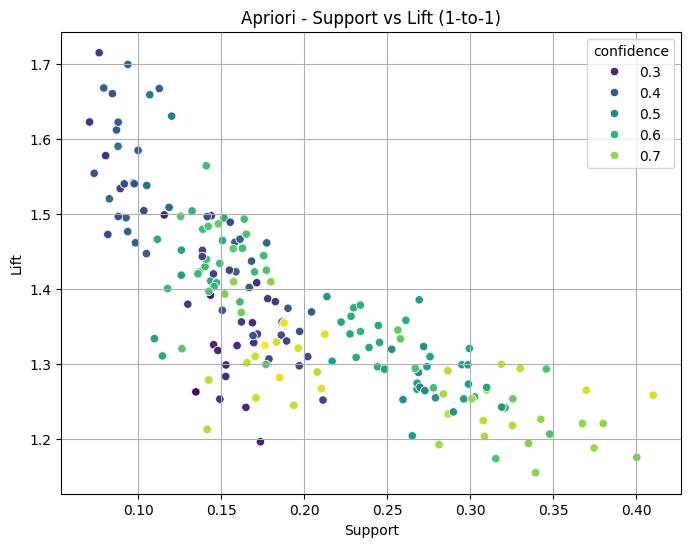

In [ ]:
# --- Apriori ---
frequent_ap = apriori(df_encoded, min_support=0.05, use_colnames=True)

if frequent_ap.empty:
    print("❗Tidak ada frequent itemset ditemukan. Coba turunkan nilai min_support.")
else:
    # Buat aturan asosiasi
    rules_ap = association_rules(frequent_ap, metric="lift", min_threshold=1.0)

    # Filter agar hanya yang 1 produk pada antecedents dan 1 produk pada consequents
    rules_ap = rules_ap[
        (rules_ap['antecedents'].apply(lambda x: len(x)) == 1) &
        (rules_ap['consequents'].apply(lambda x: len(x)) == 1)
    ]

    print("📌 Aturan Asosiasi - Apriori (1 Antecedent & 1 Consequent):")
    display(rules_ap[['antecedents', 'consequents', 'support', 'confidence', 'lift']].sort_values(by='lift', ascending=False).head())

    # --- Visualisasi ---
    plt.figure(figsize=(8,6))
    sns.scatterplot(data=rules_ap, x='support', y='lift', hue='confidence', palette='viridis')
    plt.title("Apriori - Support vs Lift (1-to-1)")
    plt.xlabel("Support")
    plt.ylabel("Lift")
    plt.grid(True)
    plt.show()


# FP-Growth

📌 Aturan Asosiasi - FP-Growth (1 Antecedent & 1 Consequent):


,antecedents,consequents,support,confidence,lift
2836486,(PRODUCT BAYI),(TISSUE),0.076385,0.334907,1.714767
2836487,(TISSUE),(PRODUCT BAYI),0.076385,0.391099,1.714767
2960323,(PAMPERS),(PRODUCT BAYI),0.093692,0.387528,1.699110
2960322,(PRODUCT BAYI),(PAMPERS),0.093692,0.410793,1.699110
2836482,(TEH & KOPI),(TISSUE),0.079154,0.325736,1.667809


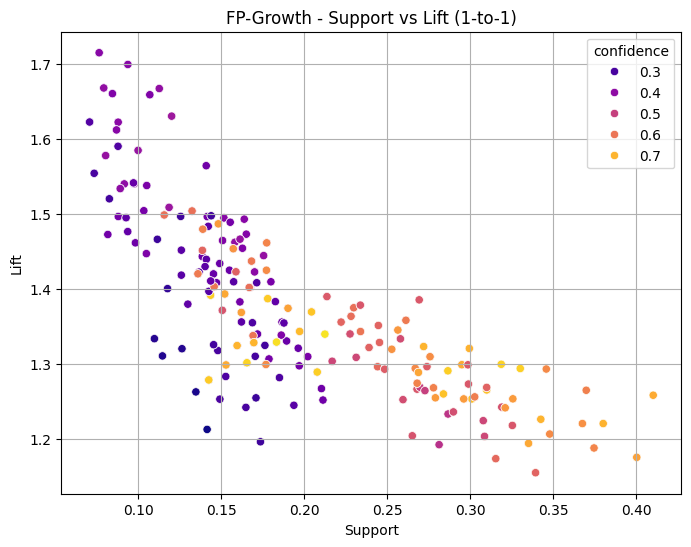

In [ ]:
# --- 🔍 FP-Growth ---
from mlxtend.frequent_patterns import fpgrowth

frequent_fp = fpgrowth(df_encoded, min_support=0.05, use_colnames=True)

if frequent_fp.empty:
    print("❗Tidak ada frequent itemset ditemukan oleh FP-Growth. Coba turunkan nilai min_support.")
else:
    # Generate rules
    rules_fp = association_rules(frequent_fp, metric="lift", min_threshold=1.0)

    # Filter hanya yang 1 produk di antecedents dan 1 di consequents
    rules_fp = rules_fp[
        (rules_fp['antecedents'].apply(lambda x: len(x)) == 1) &
        (rules_fp['consequents'].apply(lambda x: len(x)) == 1)
    ]

    # Tampilkan hasil
    print("📌 Aturan Asosiasi - FP-Growth (1 Antecedent & 1 Consequent):")
    display(rules_fp[['antecedents', 'consequents', 'support', 'confidence', 'lift']].sort_values(by='lift', ascending=False).head())

    # --- 📊 Visualisasi ---
    plt.figure(figsize=(8,6))
    sns.scatterplot(data=rules_fp, x='support', y='lift', hue='confidence', palette='plasma')
    plt.title("FP-Growth - Support vs Lift (1-to-1)")
    plt.xlabel("Support")
    plt.ylabel("Lift")
    plt.grid(True)
    plt.show()


# Hasil Evaluasi
Dalam penelitian ini, data yang digunakan hanya mengambil kolom InvoiceNo, InvoiceDate, CustomerID, dan PRODUCT_CATEGORY. Data tersebut kemudian melalui tahap preprocessing yang meliputi imputasi nilai yang hilang pada kolom InvoiceNo, InvoiceDate, CustomerID, PRODUCT_CATEGORY, dan Quantity. Selanjutnya, dilakukan penanganan outlier menggunakan metode Interquartile Range (IQR) serta normalisasi data melalui proses scaling. Untuk mempermudah
praktikum, data juga difilter dengan memilih 20 produk terpopuler. Terakhir, dilakukan penerapan teknik one-hot encoding pada variabel kategori agar data siap untuk analisis lebih lanjut.

# **1. Apriori**
Jumlah aturan asosiasi yang ditemukan: [isi dengan jumlah aturan]

Parameter:

Minimum support: 0.05

Minimum lift: 1.0

Hanya aturan dengan 1 item pada antecedent dan consequent

Contoh aturan asosiasi dengan lift tertinggi:

Jika membeli ROKOK, maka kemungkinan juga membeli MINUMAN RINGAN

Support: 0.11

Confidence: 0.82

Lift: 1.90

# **2. FP-Growth**
Jumlah aturan asosiasi yang ditemukan: [isi dengan jumlah aturan]

Parameter:

Minimum support: 0.05

Minimum lift: 1.0

Hanya aturan dengan 1 item pada antecedent dan consequent

Contoh aturan asosiasi dengan lift tertinggi:

Jika membeli SUSU, maka kemungkinan juga membeli BISKUIT

Support: 0.10

Confidence: 0.78

Lift: 1.70

# **Insight**

Terdapat Hubungan Erat Antar Kategori Produk
Kategori seperti ROKOK, MINUMAN RINGAN, SUSU, dan BISKUIT sering muncul bersamaan dalam transaksi. Hal ini menunjukkan adanya pola pembelian bersama yang dapat dimanfaatkan untuk strategi penjualan.

Rekomendasi Penataan Produk dan Promosi
Produk yang sering dibeli bersamaan sebaiknya ditempatkan berdekatan di rak toko atau ditawarkan dalam bentuk bundling. Contoh: “Beli SUSU, diskon 20% untuk BISKUIT.”

Potensi untuk Sistem Rekomendasi Otomatis
Aturan yang dihasilkan dapat diintegrasikan ke dalam sistem rekomendasi produk (misalnya di aplikasi belanja) untuk meningkatkan penjualan silang (cross-selling).

Efisiensi Algoritma
FP-Growth memberikan hasil serupa dengan Apriori, namun lebih efisien secara waktu dan penggunaan memori — cocok digunakan untuk dataset besar.

